## Key Learning Objectives:
1. Apply appropriate feature scaling (`StandardScaler`, `RobustScaler`) to continuous variables.
2. Reduce feature skewness using logarithmic transformations (`np.log1p`).
3. Encode nominal and ordinal categorical variables correctly.
4. Filter out low-variance and collinear features.
5. Rank and select top features using statistical tests (`SelectKBest`).

In [1]:
# Setup & Dataset Generation

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# Set visual style
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (9, 5)

# Seed for reproducibility
np.random.seed(2026)
n_samples = 300

# Synthetic Financial Credit Scoring Dataset
age = np.random.normal(loc=42, scale=12, size=n_samples).round()
annual_income = np.random.exponential(scale=60000, size=n_samples) + 20000  # Skewed
credit_score = np.random.uniform(300, 850, size=n_samples)
loan_amount = annual_income * np.random.uniform(0.2, 0.8, size=n_samples) # Strongly correlated with annual_income

# Categorical variables
education_level = np.random.choice(["High School", "Bachelor", "Master", "PhD"], size=n_samples, p=[0.2, 0.5, 0.2, 0.1])
home_ownership = np.random.choice(["RENT", "MORTGAGE", "OWN"], size=n_samples, p=[0.4, 0.4, 0.2])

# Constant / Quasi-constant features
country_code = [91] * n_samples  # Zero variance
has_rare_bankruptcy = [1] + [0] * (n_samples - 1)  # Quasi-constant

# Target: Default likelihood
default_prob = 1 / (1 + np.exp(-((700 - credit_score) / 100 + (loan_amount / annual_income))))
loan_default = np.random.binomial(1, default_prob)

df_credit = pd.DataFrame({
    "age": age,
    "annual_income": annual_income.round(2),
    "credit_score": credit_score.round(1),
    "loan_amount": loan_amount.round(2),
    "education_level": education_level,
    "home_ownership": home_ownership,
    "country_code": country_code,
    "has_rare_bankruptcy": has_rare_bankruptcy,
    "loan_default": loan_default
})

# Inject extreme income outliers"
df_credit.loc[[5, 25, 80], "annual_income"] = [1200000.0, 1500000.0, 2000000.0]

print("--- Credit Dataset Sample ---")
print(df_credit.head())

--- Credit Dataset Sample ---
    age  annual_income  credit_score  loan_amount education_level  \
0  37.0       62654.30         517.4     37697.20        Bachelor   
1  25.0       36173.41         529.3     17137.92        Bachelor   
2  46.0       43092.33         462.1      9394.24     High School   
3  42.0      114589.55         524.4     30700.62             PhD   
4  59.0      208167.25         431.9    121397.32        Bachelor   

  home_ownership  country_code  has_rare_bankruptcy  loan_default  
0       MORTGAGE            91                    1             1  
1           RENT            91                    0             1  
2           RENT            91                    0             1  
3       MORTGAGE            91                    0             0  
4            OWN            91                    0             1  


---
## Task 1: Handling Skewness & Scaling Continuous Features

**Instructions:**
1. Compute the skewness of `annual_income`. Apply `np.log1p()` to create a new column `log_annual_income` to fix right-skewness.
2. Apply `RobustScaler` to `log_annual_income` and `StandardScaler` to `age` and `credit_score`.

In [2]:
# Task 1 Prompt
# TODO: Calculate skewness, apply log transform, and scale continuous numerical features
# Hint: Use np.log1p() and sklearn.preprocessing scalers

# YOUR CODE HERE
from sklearn.preprocessing import RobustScaler, StandardScaler
df_credit["log_annual_income"] = np.log1p(df_credit["annual_income"])
robust_scaler = RobustScaler()
df_credit["log_annual_income"] = robust_scaler.fit_transform(df_credit[["log_annual_income"]])
standard_scaler = StandardScaler()
df_credit[["age", "credit_score"]] = standard_scaler.fit_transform(df_credit[["age", "credit_score"]])

---
## Task 2: Categorical Encoding (Nominal & Ordinal)

**Instructions:**
1. Encode `education_level` using `OrdinalEncoder` with the explicit hierarchy:
   `["High School", "Bachelor", "Master", "PhD"]`.
2. Encode `home_ownership` using `OneHotEncoder` with `drop="first"` and `sparse_output=False`.

In [3]:
# Task 2 Prompt
# TODO: Ordinal encode education_level and One-Hot encode home_ownership

# YOUR CODE HERE
from sklearn.preprocessing import OrdinalEncoder, OneHotEncoder

ordinal_encoder = OrdinalEncoder(categories=[["High School", "Bachelor", "Master", "PhD"]])
df_credit["education_level_encoded"] = ordinal_encoder.fit_transform(df_credit[["education_level"]])

onehot_encoder = OneHotEncoder(drop="first", sparse_output=False)
home_ownership_encoded = onehot_encoder.fit_transform(df_credit[["home_ownership"]])
df_credit = pd.concat([df_credit, pd.DataFrame(home_ownership_encoded, columns=onehot_encoder.get_feature_names_out(["home_ownership"]))], axis=1)

---
## Task 3: Low-Variance Feature Filtering

**Instructions:**
1. Use `VarianceThreshold(threshold=0.01)` to identify and remove constant or quasi-constant numerical features (`country_code`, `has_rare_bankruptcy`).
2. Print the list of dropped features and retained features.

In [4]:
# Task 3 Prompt
# TODO: Apply VarianceThreshold to drop low-variance columns

# YOUR CODE HERE
from sklearn.feature_selection import VarianceThreshold
selector = VarianceThreshold(threshold=0.01)
numerical_features = df_credit.select_dtypes(include=[np.number]).drop(columns=["loan_default"])
selector.fit(numerical_features)
retained_features = numerical_features.columns[selector.get_support()]
dropped_features = numerical_features.columns[~selector.get_support()]
print("Dropped Features:", list(dropped_features))
print("Retained Features:", list(retained_features))

Dropped Features: ['country_code', 'has_rare_bankruptcy']
Retained Features: ['age', 'annual_income', 'credit_score', 'loan_amount', 'log_annual_income', 'education_level_encoded', 'home_ownership_OWN', 'home_ownership_RENT']


---
## Task 4: Removing Highly Collinear Features

**Instructions:**
1. Calculate the Pearson correlation matrix for numerical features.
2. Identify features with absolute correlation $|r| > 0.85$ (e.g., `annual_income` vs `loan_amount`) and drop the redundant column.

In [5]:
# Task 4 Prompt

# TODO: Detect and drop collinear features with |r| > 0.85

# YOUR CODE HERE
correlation_matrix = numerical_features.corr()
highly_collinear_features = correlation_matrix[(correlation_matrix.abs() > 0.85) & (correlation_matrix.abs() < 1)].any()
dropped_features = numerical_features.columns[highly_collinear_features]
numerical_features = numerical_features.drop(columns=dropped_features)
retained_features = numerical_features.columns

---
## Task 11: Statistical Feature Selection (`SelectKBest`)

**Instructions:**
1. Rank all remaining numerical features against the target `loan_default` using `SelectKBest` with `f_classif` (ANOVA F-Test) and `mutual_info_classif`.
2. Plot a comparative bar chart showing feature importance scores.
3. *Note:* Remember to specify `hue` and set `legend=False` in Seaborn barplots to prevent deprecation warnings.

/home/shinkhal/PycharmProjects/pgcp-da/.venv/lib64/python3.13/site-packages/sklearn/feature_selection/_univariate_selection.py:110: UserWarning: Features [4] are constant.
  warnings.warn("Features %s are constant." % constant_features_idx, UserWarning)
/home/shinkhal/PycharmProjects/pgcp-da/.venv/lib64/python3.13/site-packages/sklearn/feature_selection/_univariate_selection.py:111: RuntimeWarning: invalid value encountered in divide
  f = msb / msw
/tmp/ipykernel_111188/1493238141.py:26: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend(title="Score Type")


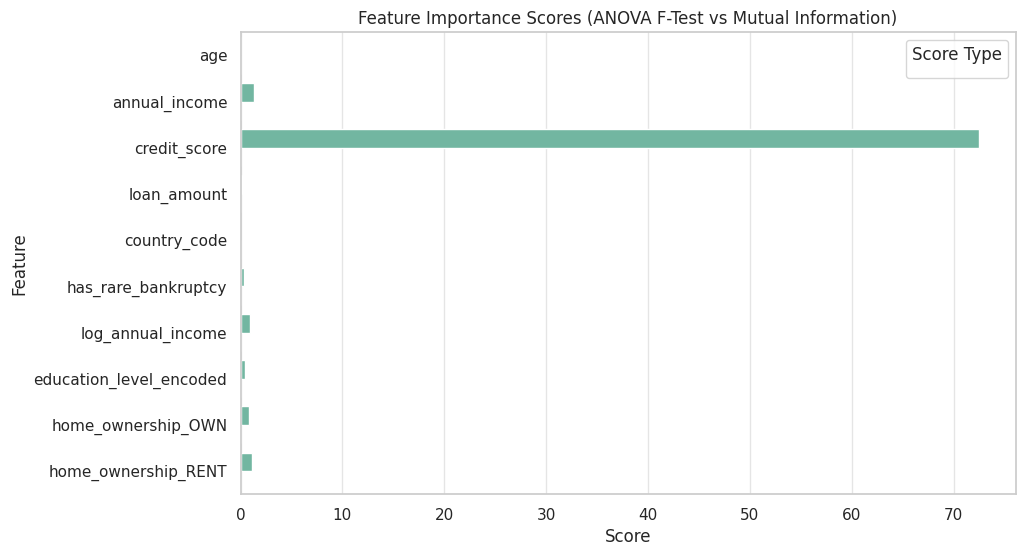

In [6]:
# Task 5 Prompt

# TODO: Rank features using SelectKBest (f_classif and mutual_info_classif) and plot the scores

# YOUR CODE HERE
from sklearn.feature_selection import SelectKBest, f_classif, mutual_info_classif
X = numerical_features
y = df_credit["loan_default"]
# ANOVA F-Test
anova_selector = SelectKBest(score_func=f_classif, k="all")
anova_selector.fit(X, y)
anova_scores = pd.DataFrame({"Feature": X.columns, "ANOVA_F_Score": anova_selector.scores_})
# Mutual Information
mi_selector = SelectKBest(score_func=mutual_info_classif, k="all")
mi_selector.fit(X, y)
mi_scores = pd.DataFrame({"Feature": X.columns, "Mutual_Info_Score": mi_selector.scores_})
# Merge scores
feature_scores = pd.merge(anova_scores, mi_scores, on="Feature")
# Plotting
feature_scores_melted = feature_scores.melt(id_vars="Feature", var_name="Score_Type", value_name="Score")
plt.figure(figsize=(10, 6))
sns.barplot(x="Score", y="Feature", hue="Score_Type", data=feature_scores_melted, palette="Set2", legend=False)
plt.title("Feature Importance Scores (ANOVA F-Test vs Mutual Information)")
plt.xlabel("Score")
plt.ylabel("Feature")
plt.legend(title="Score Type")
plt.show()